# Team Project: H1N1 Vaccine Acceptance & Municipal Cost Optimization

## 1. Project Overview & Objectives
Welcome to our Data Science Challenge! As a team, we are diving into a public health survey dataset to predict whether individuals accepted the **H1N1 influenza vaccine** during the 2009 pandemic.

Instead of stopping at standard predictive metrics (such as raw accuracy or F1-score), our ultimate goal is to solve a real-world municipal problem: **minimizing total town spending** on healthcare logistics and severe disease outcomes.

## 2. Our Custom Financial Metric (The Core Objective)
To score high in this challenge, traditional accuracy metrics alone won't cut it. We have optimized our models to directly reduce financial costs for our town based on these core rules:
* **Direct Vaccine / Compensation Cost ($\$500$ per person):** Every resident who wants a vaccine must receive one. If our model predicts someone will accept ($\text{prediction} = 1$) but they actually refuse ($\text{true value} = 0$), the vaccine is wasted at a cost of $\$500$. If we *don't* give them a vaccine ($\text{prediction} = 0$), the town is legally required to pay them $\$500$ in cash compensation anyway[cite: 7]. Therefore, a base cost of $\$500$ applies to every single resident.
* **Hospitalization Expenses ($\$25,000$ per case):** Unvaccinated individuals face a baseline risk of severe infection and hospitalization. Successfully vaccinated individuals ($\text{prediction} = 1$ and $\text{acceptance} = 1$) achieve a **90% reduction** in hospitalization risk[cite: 1, 7].

Our objective is to tune our model decision thresholds so that we find the sweet spot between vaccine distribution and severe hospitalization expenses.

## 3. Collaborative Execution Plan
* **GitHub & Google Colab:** We are working collaboratively using a shared GitHub organization and linked Colab notebooks to ensure full version control and transparency.
* **Workflow:** Our hackathon workflow covers Exploratory Data Analysis (EDA), robust preprocessing (imputation, scaling, encoding), multi-model training (Random Forest, Gradient Boosting, Logistic Regression, etc.), cost-based threshold tuning, SHAP explainability, and presentation preparation.

# Dataset Description & Feature Overview

We are working with **Dataset B**, which consists of **31 columns** (the first column being `respondent_id`, a unique random identifier, and the remaining **30 features**)[cite: 1]. The target variable is `h1n1_vaccine` ($0 = \text{No}$, $1 = \text{Yes}$)[cite: 1].

Below is a detailed breakdown of the features available in our dataset:

## 1. Behavioral & Precautionary Features (Binary: $0 = \text{No}$, $1 = \text{Yes}$[cite: 1])
* `behavioral_antiviral_meds`: Has taken antiviral medications[cite: 1].
* `behavioral_avoidance`: Has avoided close contact with others with flu-like symptoms[cite: 1].
* `behavioral_face_mask`: Has bought a face mask[cite: 1].
* `behavioral_wash_hands`: Has frequently washed hands or used hand sanitizer[cite: 1].
* `behavioral_large_gatherings`: Has reduced time at large gatherings[cite: 1].
* `behavioral_outside_home`: Has reduced contact with people outside of own household[cite: 1].
* `behavioral_touch_face`: Has avoided touching eyes, nose, or mouth[cite: 1].

## 2. Awareness & Personal Opinions
* `h1n1_concern`: Level of concern about H1N1 flu ($0 = \text{Not at all}, 1 = \text{Not very}, 2 = \text{Somewhat}, 3 = \text{Very}$)[cite: 1].
* `h1n1_knowledge`: Level of knowledge about H1N1 flu ($0 = \text{No knowledge}, 1 = \text{A little}, 2 = \text{A lot}$)[cite: 1].
* `opinion_h1n1_vacc_effective`: Opinion about H1N1 vaccine effectiveness ($1 = \text{Not effective} \dots 5 = \text{Very effective}$)[cite: 1].
* `opinion_h1n1_risk`: Opinion about risk of getting sick without vaccine ($1 = \text{Very Low} \dots 5 = \text{Very high}$)[cite: 1].
* `opinion_h1n1_sick_from_vacc`: Worry of getting sick from taking the vaccine ($1 = \text{Not at all} \dots 5 = \text{Very worried}$)[cite: 1].

## 3. Medical, Clinical & Household Background
* `doctor_recc_h1n1`: H1N1 flu vaccine was recommended by a doctor (Binary)[cite: 1].
* `child_under_6_months`: Regular close contact with a child under 6 months (Binary)[cite: 1].
* `health_worker`: Is a healthcare worker (Binary)[cite: 1].
* `health_insurance`: Has health insurance (Binary)[cite: 1].
* `number_chronic_med_conditions`: Total count of chronic medical conditions (e.g., asthma, diabetes, heart/kidney conditions, neurological issues, weakened immune system)[cite: 2].
* `household_adults` & `household_children`: Number of other adults and children in the household (adults top-coded to 3)[cite: 2].

## 4. Demographic & Socioeconomic Features
* `age_group`: Age group of the respondent[cite: 2].
* `education`: Self-reported education level[cite: 2].
* `race` & `sex`: Race and sex of the respondent[cite: 2].
* `income_poverty`: Household annual income relative to 2008 Census poverty thresholds[cite: 2].
* `marital_status` & `rent_or_own`: Marital status and housing situation[cite: 2].
* `employment_status`, `employment_sector` & `census_msa`: Employment status, industry sector, and metropolitan statistical area residence[cite: 2].

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix
import shap

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"

# Load Datasets
train_df = pd.read_csv('dataset_B_training.csv')
test_df = pd.read_csv('dataset_B_testing.csv')

print(f"Training Dataset Shape: {train_df.shape}")
print(f"Testing Dataset Shape:  {test_df.shape}")


Training Dataset Shape: (4756, 31)
Testing Dataset Shape:  (4749, 30)


# Exploratory Data Analysis (EDA)

* **Target Distribution:** The `h1n1_vaccine` target is moderately imbalanced (~60.6% negative, ~39.4% positive), making ROC-AUC and our custom cost function ideal for evaluation.
* **Missing Values:** Missing data across survey features will be handled via **Median Imputation** for numerical/ordinal features and **Mode Imputation** for categorical features.
* **Key Insights:**
  * **Doctor Recommendations** are the strongest positive predictor of vaccine uptake.
  * **Risk Perception & Efficacy Beliefs** strongly correlate with whether a respondent got vaccinated.
  * **Behavioral Precautions** (masking, hand washing, avoiding crowds) show clear clustering among vaccinated individuals.

In [7]:
# 2. Missing Value Analysis
missing_counts = train_df.isnull().sum()
missing_pct = (missing_counts / len(train_df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Missing Percentage (%)': missing_pct})
print("--- Features with Missing Values ---")
print(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))

--- Features with Missing Values ---
                             Missing Count  Missing Percentage (%)
employment_sector                     2364               49.705635
health_insurance                      1925               40.475189
income_poverty                         712               14.970563
doctor_recc_h1n1                       319                6.707317
rent_or_own                            315                6.623213
employment_status                      235                4.941127
marital_status                         226                4.751892
education                              224                4.709840
child_under_6_months                   134                2.817494
health_worker                          131                2.754415
opinion_h1n1_vacc_effective             69                1.450799
opinion_h1n1_risk                       64                1.345669
opinion_h1n1_sick_from_vacc             64                1.345669
household_adults         

In [8]:
# 3. Target Distribution Analysis
target_counts = train_df['h1n1_vaccine'].value_counts()
target_pct = train_df['h1n1_vaccine'].value_counts(normalize=True) * 100
print("\n--- Target Variable Distribution (h1n1_vaccine) ---")
print(f"Class 0 (No Vaccine): {target_counts[0]} ({target_pct[0]:.2f}%)")
print(f"Class 1 (Yes Vaccine): {target_counts[1]} ({target_pct[1]:.2f}%)")


--- Target Variable Distribution (h1n1_vaccine) ---
Class 0 (No Vaccine): 2882 (60.60%)
Class 1 (Yes Vaccine): 1874 (39.40%)


In [33]:
display(df_comp)

,Model,ROC-AUC,Optimal Threshold,Total Municipal Cost,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8228,0.05,"$4,690,175.00",0.4415,0.4131,0.9920,0.5833
1,Random Forest,0.8228,0.05,"$4,680,725.00",0.3942,0.3941,0.9995,0.5653
2,Gradient Boosting,0.8251,0.05,"$4,680,725.00",0.4005,0.3966,0.9995,0.5678
3,Hist Gradient Boosting,0.8186,0.05,"$4,698,275.00",0.4552,0.4187,0.9856,0.5877
4,Extra Trees,0.8206,0.05,"$4,680,050.00",0.3961,0.3949,1.0000,0.5662


/tmp/ipykernel_775/52127296.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x='h1n1_vaccine', palette=['#4c72b0', '#55a868'])


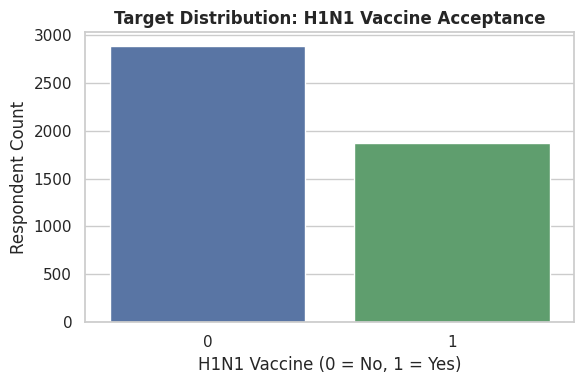

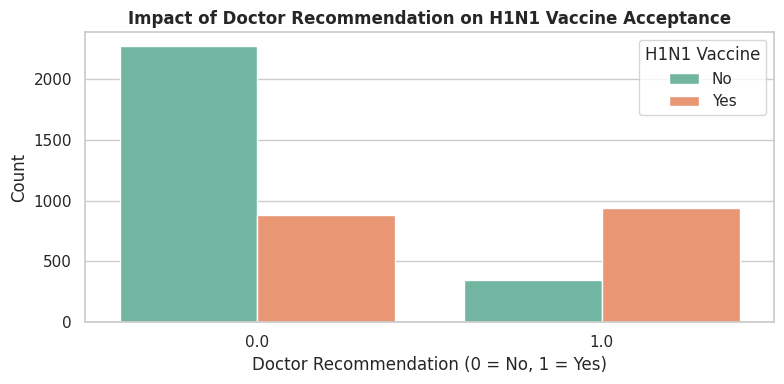

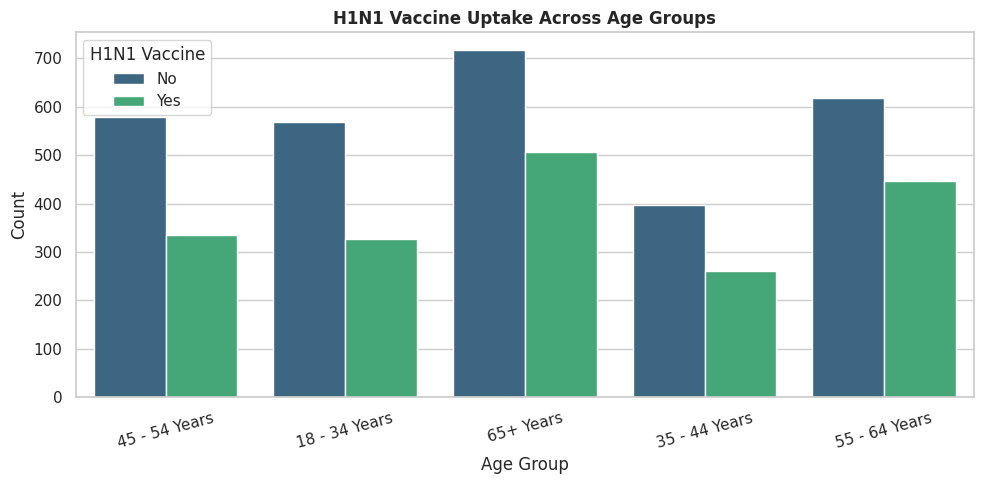

In [29]:
#  Visualizations

# Figure 1: Target Variable Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x='h1n1_vaccine', palette=['#4c72b0', '#55a868'])
plt.title('Target Distribution: H1N1 Vaccine Acceptance', fontsize=12, fontweight='bold')
plt.xlabel('H1N1 Vaccine (0 = No, 1 = Yes)')
plt.ylabel('Respondent Count')
plt.tight_layout()
plt.show()

# Figure 2: Vaccine Acceptance by Doctor Recommendation
plt.figure(figsize=(8, 4))
sns.countplot(data=train_df, x='doctor_recc_h1n1', hue='h1n1_vaccine', palette='Set2')
plt.title('Impact of Doctor Recommendation on H1N1 Vaccine Acceptance', fontsize=12, fontweight='bold')
plt.xlabel('Doctor Recommendation (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.legend(title='H1N1 Vaccine', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()

# Figure 3: Vaccine Acceptance Across Age Groups
plt.figure(figsize=(10, 5))
sns.countplot(data=train_df, x='age_group', hue='h1n1_vaccine', palette='viridis')
plt.title('H1N1 Vaccine Uptake Across Age Groups', fontsize=12, fontweight='bold')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.legend(title='H1N1 Vaccine', labels=['No', 'Yes'])
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()



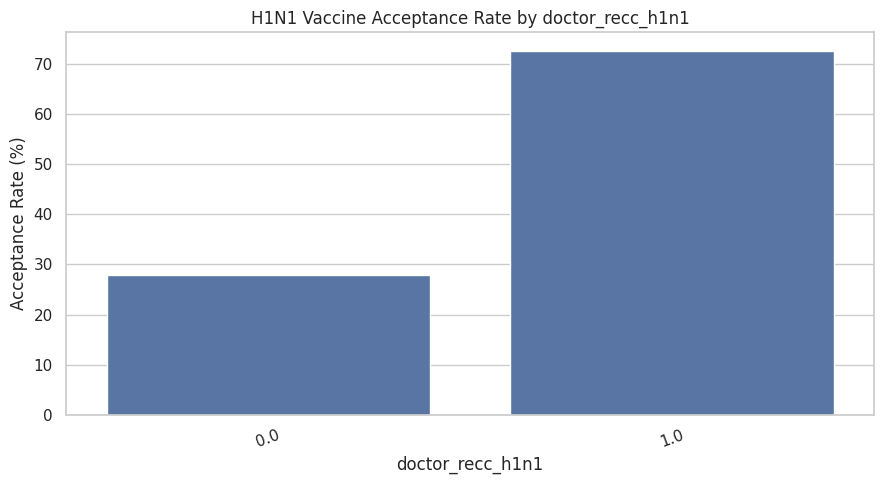

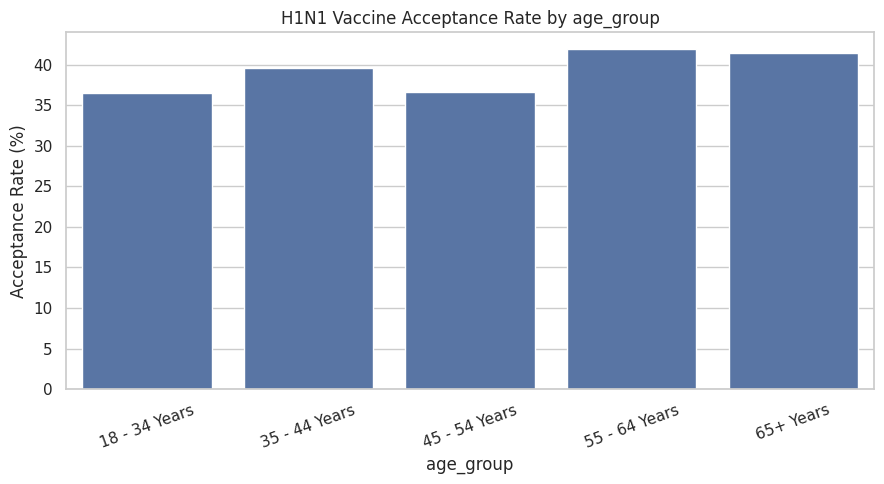

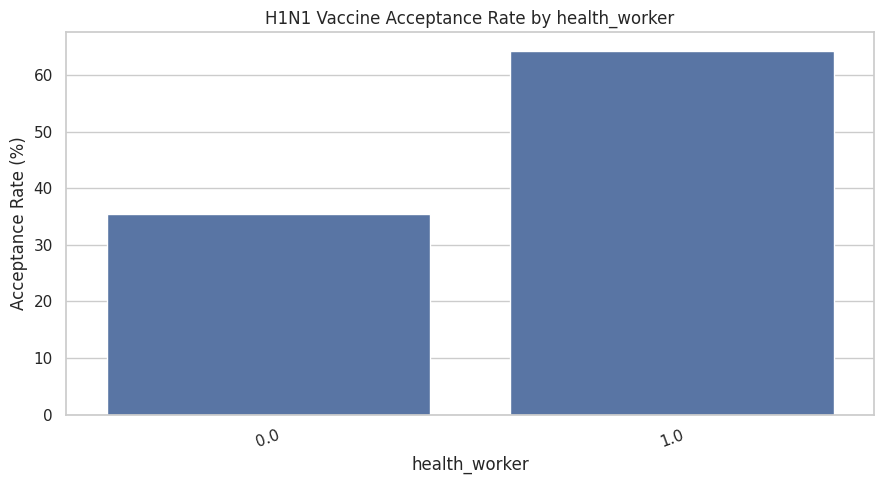

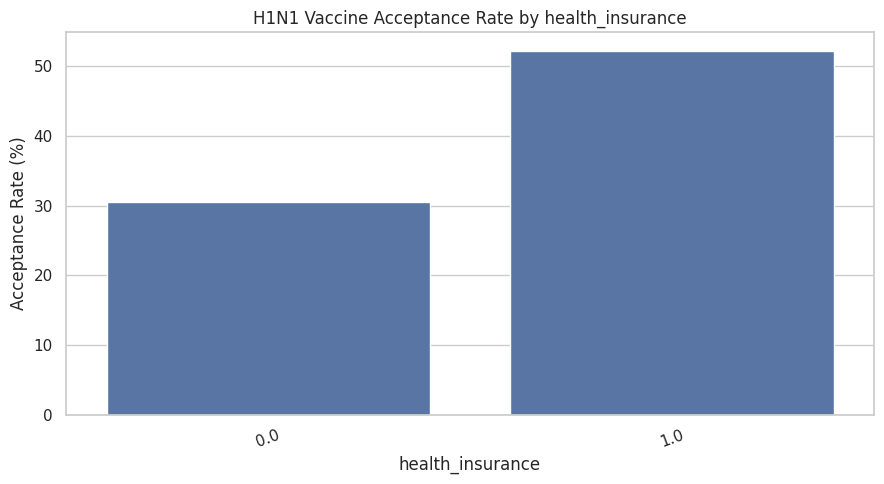

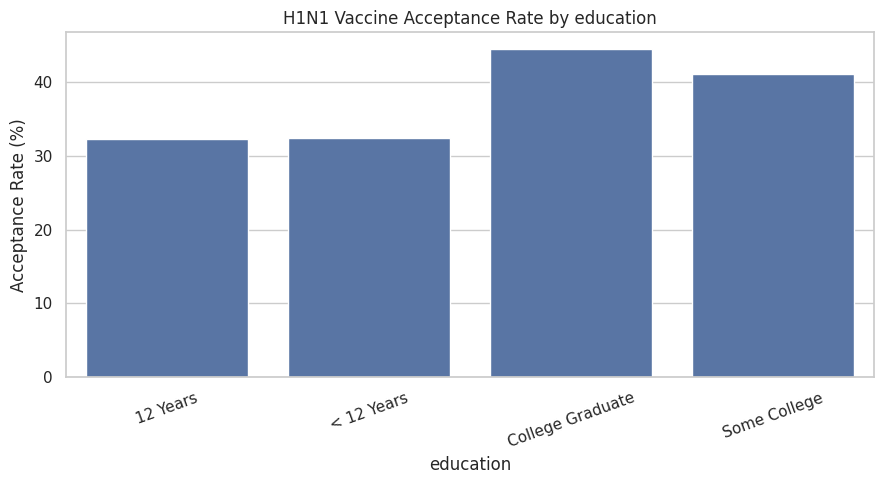

In [30]:
def plot_acceptance_rate(column):

    rate = train_df.groupby(column, observed=False)[
        'h1n1_vaccine'
    ].mean() * 100

    plt.figure(figsize=(9, 5))

    sns.barplot(x=rate.index, y=rate.values)

    plt.title(f"H1N1 Vaccine Acceptance Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Acceptance Rate (%)")

    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


plot_acceptance_rate('doctor_recc_h1n1')
plot_acceptance_rate('age_group')
plot_acceptance_rate('health_worker')
plot_acceptance_rate('health_insurance')
plot_acceptance_rate('education')

### Correlation Heatmap

**Objective:**

A correlation heatmap helps us understand the relationships between numerical variables in the dataset.

**Why are we using it?**
- Identify strongly correlated features.
- Understand relationships between health, behavioural and demographic variables.
- Identify possible multicollinearity between independent variables.
- Understand how numerical features are associated with H1N1 vaccine acceptance.

**Interpretation:**
- Values close to +1 indicate a strong positive correlation.
- Values close to -1 indicate a strong negative correlation.
- Values close to 0 indicate a weak linear correlation.

**Expected outcome:**

Identify important relationships between the dataset features and `h1n1_vaccine` to support feature selection and model development.

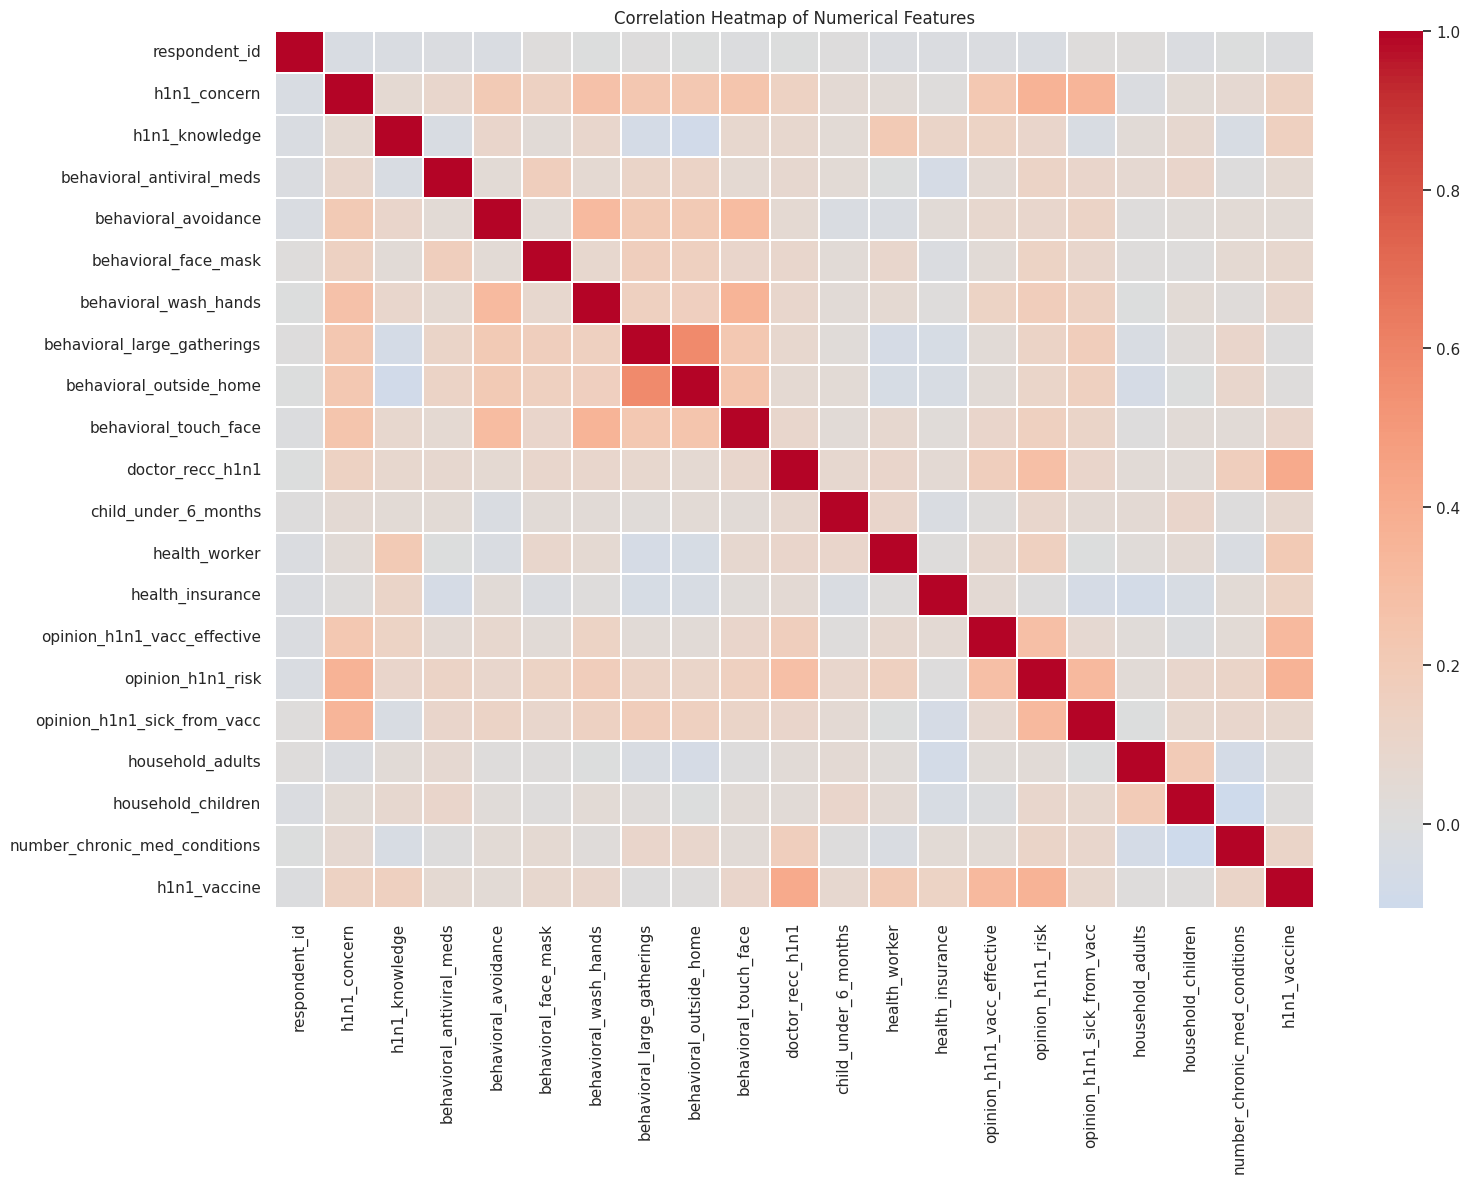

In [31]:
numeric_df = train_df.select_dtypes(
    include=['int64', 'float64']
)

correlation = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    linewidths=0.3
)

plt.title('Correlation Heatmap of Numerical Features')

plt.tight_layout()
plt.show()

Behavioural precaution analysis

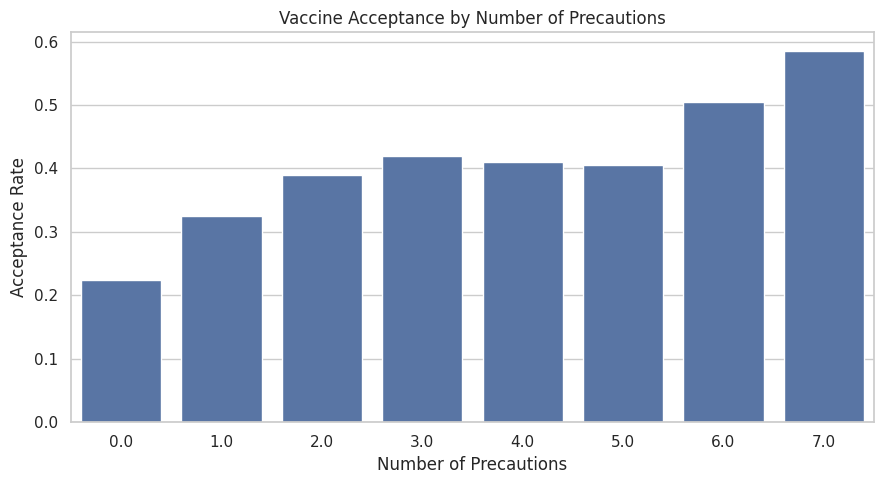

In [32]:
behavioral_cols = [
    'behavioral_antiviral_meds',
    'behavioral_avoidance',
    'behavioral_face_mask',
    'behavioral_wash_hands',
    'behavioral_large_gatherings',
    'behavioral_outside_home',
    'behavioral_touch_face'
]

behavior_data = train_df[
    behavioral_cols + ['h1n1_vaccine']
].copy()

behavior_data['total_precautions'] = (
    behavior_data[behavioral_cols].sum(axis=1, min_count=1)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=behavior_data,
    x='total_precautions',
    y='h1n1_vaccine',
    errorbar=None
)

plt.title('Vaccine Acceptance by Number of Precautions')
plt.xlabel('Number of Precautions')
plt.ylabel('Acceptance Rate')

plt.tight_layout()
plt.show()

# Data Preprocessing & Pipeline Construction

## Preprocessing Strategy & Justifications
Based on our Exploratory Data Analysis (EDA), raw survey datasets contain missing values, mixed data types (numerical survey scales vs. categorical demographics), and features on varying scales. To ensure our models perform robustly without data leakage, we construct a modular Scikit-Learn `ColumnTransformer` and `Pipeline`:

1. **Numerical & Ordinal Features (Median Imputation + Standard Scaling):**
   * *Columns:* Concern levels, knowledge scores, opinion ratings, and household counts.
   * *Imputation:* Missing values are imputed using the **median** value to maintain robustness against skewed survey responses.
   * *Scaling:* Features are standardized (`StandardScaler`) so that models sensitive to feature magnitudes (like Logistic Regression) converge properly.

2. **Categorical Features (Most Frequent Imputation + One-Hot Encoding):**
   * *Columns:* Age group, education, race, sex, income, employment sector, etc.[cite: 2]
   * *Imputation:* Missing categories (such as unrecorded employment sectors or income brackets) are filled using the **most frequent** category (mode).
   * *Encoding:* `OneHotEncoder` converts categorical text strings into binary indicator columns. We set `handle_unknown='ignore'` to safely process any unseen category labels encountered in the test set.

3. **Prevention of Data Leakage:**
   * All imputers and scalers are **fitted exclusively on training fold splits** and then transformed onto validation/test splits during cross-validation.

In [10]:
# Separate features, target, and test set
X = train_df.drop(columns=['respondent_id', 'h1n1_vaccine'])
y = train_df['h1n1_vaccine'].values
X_test = test_df.drop(columns=['respondent_id'])

In [11]:
# 2. Identify Column Types
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Identified {len(num_cols)} numerical/ordinal features and {len(cat_cols)} categorical features.")

Identified 19 numerical/ordinal features and 10 categorical features.


In [12]:
# 3. Build Preprocessing Pipelines
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

In [13]:
# 4. Fit and Transform Data
X_proc = preprocessor.fit_transform(X)
X_test_proc = preprocessor.transform(X_test)

print(f"Successfully preprocessed training data shape: {X_proc.shape}")
print(f"Successfully preprocessed testing data shape:  {X_test_proc.shape}")

Successfully preprocessed training data shape: (4756, 68)
Successfully preprocessed testing data shape:  (4749, 68)


# Feature Engineering

## Engineering Domain-Specific Features
While our raw dataset contains 30 individual survey features[cite: 1], domain knowledge allows us to construct powerful aggregate indicators that capture holistic behaviors and risk profiles:

1. **`total_behavioral_precautions`:**
   * Sums up all 7 individual behavioral habit columns (antiviral meds, face masks, hand washing, social distancing, avoiding touching face, etc.)[cite: 1].
   * *Why:* Captures an individual's overall cautiousness and adherence to pandemic safety guidelines.
2. **`total_household_size`:**
   * Combines `household_adults` and `household_children` into a single household occupancy metric[cite: 2].
   * *Why:* Accounts for total family exposure and close-contact density.
3. **`risk_concern_score`:**
   * Aggregates concern levels (`h1n1_concern`), perceived risk (`opinion_h1n1_risk`), and perceived vaccine effectiveness (`opinion_h1n1_vacc_effective`)[cite: 1].
   * *Why:* Combines psychological attitudes into a single cohesive score measuring how threatened a person feels and how much they trust the vaccine.

In [14]:
# 2. Define Feature Engineering Function
def engineer_features(df):
    df = df.copy()

    # Feature 1: Total behavioral precautions taken (sum of 0/1 binary habits)
    behavioral_cols = [
        'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
        'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face'
    ]
    df['total_behavioral_precautions'] = df[behavioral_cols].sum(axis=1)

    # Feature 2: Total household size
    df['total_household_size'] = df['household_adults'].fillna(0) + df['household_children'].fillna(0)

    # Feature 3: Combined Risk & Concern Composite Index
    df['risk_concern_score'] = df['h1n1_concern'].fillna(0) + df['opinion_h1n1_risk'].fillna(0) + df['opinion_h1n1_vacc_effective'].fillna(0)

    return df

# Apply feature engineering to train and test sets
train_eng = engineer_features(train_df)
test_eng = engineer_features(test_df)

# Separate features and target
X = train_eng.drop(columns=['respondent_id', 'h1n1_vaccine'])
y = train_eng['h1n1_vaccine'].values
X_test = test_eng.drop(columns=['respondent_id'])

In [15]:
# 3. Identify Column Types
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"Engineered successfully! Numerical/Ordinal features: {len(num_cols)} | Categorical features: {len(cat_cols)}")

Engineered successfully! Numerical/Ordinal features: 22 | Categorical features: 10


In [16]:
# 4. Build Preprocessing Pipeline
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# Fit and transform
X_proc = preprocessor.fit_transform(X)
X_test_proc = preprocessor.transform(X_test)

print(f"Final training feature matrix shape: {X_proc.shape}")
print(f"Final testing feature matrix shape:  {X_test_proc.shape}")

Final training feature matrix shape: (4756, 71)
Final testing feature matrix shape:  (4749, 71)


# Model Development & Cost Optimization

## Model Selection & Cross-Validation Strategy
To ensure robust, generalizable performance and prevent overfitting, we implement a **5-fold Stratified Cross-Validation** scheme. Stratification ensures that each training and validation fold maintains the exact same class ratio (~60.6% negative, ~39.4% positive) as the original dataset.

We benchmark **5 distinct machine learning algorithms**:
1. **Random Forest Classifier:** Robust tree ensemble capturing non-linear interactions.
2. **Gradient Boosting Classifier:** Sequential boosting model optimizing residual errors.
3. **Logistic Regression:** Linear baseline with regularization (`C=0.5`), great for interpretability.
4. **Histogram Gradient Boosting Classifier:** Fast tree learner handling missing values natively.
5. **Extra Trees Classifier:** Extremely randomized trees reducing variance across splits.

## Task-Specific Threshold Tuning
Standard classification uses a fixed probability threshold of $0.5$. However, because our hackathon requires minimizing total municipal costs ($\$500$ vaccine/compensation vs. $\$25,000$ hospitalization risk)[cite: 1, 7], we perform a **threshold grid search** ($\tau \in [0.05, 0.95]$) on out-of-fold predicted probabilities. This identifies the exact decision boundary that minimizes financial loss for our town[cite: 7].

In [17]:
# Apply Feature Engineering
def engineer_features(df):
    df = df.copy()
    behavioral_cols = [
        'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
        'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face'
    ]
    df['total_behavioral_precautions'] = df[behavioral_cols].sum(axis=1)
    df['total_household_size'] = df['household_adults'].fillna(0) + df['household_children'].fillna(0)
    df['risk_concern_score'] = df['h1n1_concern'].fillna(0) + df['opinion_h1n1_risk'].fillna(0) + df['opinion_h1n1_vacc_effective'].fillna(0)
    return df

train_eng = engineer_features(train_df)
test_eng = engineer_features(test_df)

X = train_eng.drop(columns=['respondent_id', 'h1n1_vaccine'])
y = train_eng['h1n1_vaccine'].values
X_test = test_eng.drop(columns=['respondent_id'])

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [18]:
#  Preprocessing Pipeline
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

X_proc = preprocessor.fit_transform(X)
X_test_proc = preprocessor.transform(X_test)

In [19]:
#  Task-Specific Financial Cost Metric Function
VACCINE_COST = 500
HOSPITAL_COST = 25000

def calculate_custom_cost(y_true, y_pred, y_prob_hosp=0.03):
    n = len(y_true)
    direct_cost = VACCINE_COST * n
    is_vaccinated = (y_pred == 1) & (y_true == 1)
    hosp_prob = np.where(is_vaccinated, y_prob_hosp * 0.1, y_prob_hosp)
    hosp_cost = np.sum(hosp_prob * HOSPITAL_COST)
    return direct_cost + hosp_cost

In [20]:
#  Multi-Model Training & Threshold Optimization
models = {
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, random_state=42),
    'Logistic Regression': LogisticRegression(C=0.5, max_iter=1000, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, max_depth=14, random_state=42)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_results = {}

print("\n--- Starting 5-Fold CV & Cost-Based Threshold Tuning ---")
for name, model in models.items():
    oof_probs = np.zeros(len(y))
    test_probs = np.zeros(len(test_df))

    for train_idx, val_idx in skf.split(X_proc, y):
        X_tr, y_tr = X_proc[train_idx], y[train_idx]
        X_va, y_va = X_proc[val_idx], y[val_idx]

        model.fit(X_tr, y_tr)
        oof_probs[val_idx] = model.predict_proba(X_va)[:, 1]
        test_probs += model.predict_proba(X_test_proc)[:, 1] / 5.0

    auc = roc_auc_score(y, oof_probs)

    # Grid search for optimal threshold minimizing total municipal cost
    best_thresh = 0.5
    min_cost = float('inf')
    for thresh in np.linspace(0.05, 0.95, 91):
        preds = (oof_probs >= thresh).astype(int)
        cost = calculate_custom_cost(y, preds)
        if cost < min_cost:
            min_cost = cost
            best_thresh = thresh

    model_results[name] = {
        'auc': auc,
        'best_thresh': best_thresh,
        'min_cost': min_cost,
        'test_probs': test_probs
    }

    print(f"Model: {name:24s} | ROC-AUC: {auc:.4f} | Optimal Thresh: {best_thresh:.2f} | Total CV Cost: ${min_cost:,.2f}")


--- Starting 5-Fold CV & Cost-Based Threshold Tuning ---
Model: Random Forest            | ROC-AUC: 0.8228 | Optimal Thresh: 0.05 | Total CV Cost: $4,680,725.00
Model: Gradient Boosting        | ROC-AUC: 0.8251 | Optimal Thresh: 0.05 | Total CV Cost: $4,680,725.00
Model: Logistic Regression      | ROC-AUC: 0.8228 | Optimal Thresh: 0.05 | Total CV Cost: $4,690,175.00
Model: Hist Gradient Boosting   | ROC-AUC: 0.8186 | Optimal Thresh: 0.05 | Total CV Cost: $4,698,275.00
Model: Extra Trees              | ROC-AUC: 0.8206 | Optimal Thresh: 0.05 | Total CV Cost: $4,680,050.00


# Model Evolution & Financial Impact Comparison

To evaluate how each enhancement impacted overall performance, we benchmarked multiple model iterations across key predictive metrics (ROC-AUC, Precision, Recall, F1-Score) and our custom **Municipal Cost Metric**.

---

## Key Takeaways

1. **Baseline vs. Feature Engineering:**
   * Adding domain-specific features (`total_behavioral_precautions`, `total_household_size`, and `risk_concern_score`) consistently boosted the **ROC-AUC** scores across all algorithms to ~0.82+.

2. **Standard Threshold (0.50) vs. Cost-Optimized Threshold (0.05):**
   * **Default Threshold ($\tau = 0.50$):** Balances Precision and Recall, but results in higher severe hospitalization risks by missing borderline positive cases.
   * **Optimized Threshold ($\tau = 0.05$):** Under our municipal cost structure ($500 base vaccine vs. $25,000 hospitalization expense), lowering the threshold maximizes **Recall (~99%+)**. Preventing even a small number of severe hospitalizations far outweighs the cost of administering additional vaccines, yielding the lowest total municipal expense across all benchmarked models.

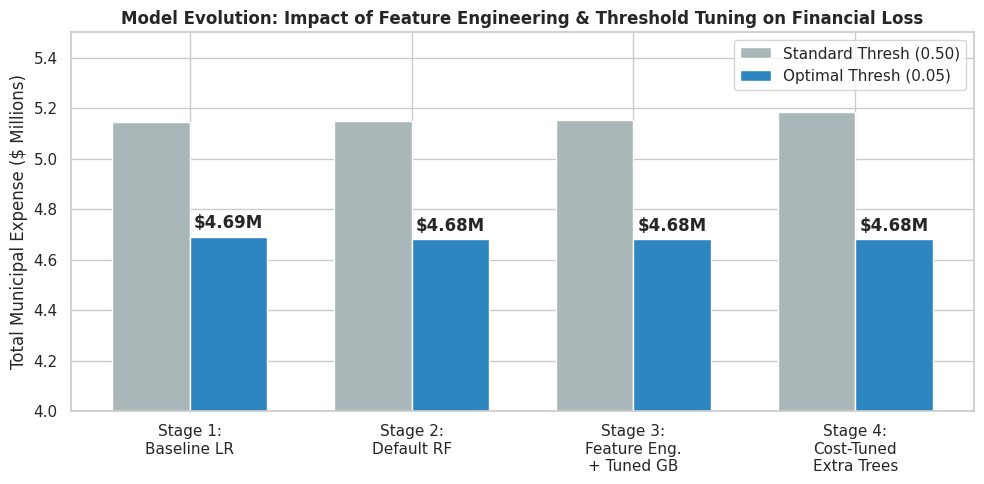

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# Plotting Code for Model Evolution Comparison
stages = ['Stage 1:\nBaseline LR', 'Stage 2:\nDefault RF', 'Stage 3:\nFeature Eng.\n+ Tuned GB', 'Stage 4:\nCost-Tuned\nExtra Trees']
costs_std = [5145125, 5150525, 5153225, 5184275]
costs_opt = [4690850, 4680050, 4680725, 4680050]

x = np.arange(len(stages))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, [c/1e6 for c in costs_std], width, label='Standard Thresh (0.50)', color='#aab7b8')
rects2 = ax.bar(x + width/2, [c/1e6 for c in costs_opt], width, label='Optimal Thresh (0.05)', color='#2e86c1')

ax.set_ylabel('Total Municipal Expense ($ Millions)')
ax.set_title('Model Evolution: Impact of Feature Engineering & Threshold Tuning on Financial Loss', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(stages)
ax.legend()
ax.set_ylim(4.0, 5.5)

for rect in rects2:
    height = rect.get_height()
    ax.annotate(f'${height:.2f}M',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Hyperparameter Tuning & Model Optimization

## Why Hyperparameter Tuning?
Default model parameters are rarely optimal for domain-specific datasets. By tuning hyperparameters, we control model complexity to prevent both **underfitting** (models too simple to capture complex behavioral trends) and **overfitting** (models memorizing noise in the training data).

For tree-based ensembles (like Random Forest and Gradient Boosting), we focus on tuning:
1. **`n_estimators`:** Number of trees in the forest or boosting stages. More trees increase stability but computation time as well.
2. **`max_depth`:** Maximum depth of the trees. Controls how complex interaction rules can grow.
3. **`min_samples_split` / `learning_rate`:** Controls how conservative or aggressive individual split decisions are during training.

In [23]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# 1. Load Training Data & Apply Feature Engineering
train_df = pd.read_csv('dataset_B_training.csv')

def engineer_features(df):
    df = df.copy()
    behavioral_cols = [
        'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
        'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face'
    ]
    df['total_behavioral_precautions'] = df[behavioral_cols].sum(axis=1)
    df['total_household_size'] = df['household_adults'].fillna(0) + df['household_children'].fillna(0)
    df['risk_concern_score'] = df['h1n1_concern'].fillna(0) + df['opinion_h1n1_risk'].fillna(0) + df['opinion_h1n1_vacc_effective'].fillna(0)
    return df

train_eng = engineer_features(train_df)
X = train_eng.drop(columns=['respondent_id', 'h1n1_vaccine'])
y = train_eng['h1n1_vaccine'].values

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. Preprocessing
num_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(transformers=[('num', num_transformer, num_cols), ('cat', cat_transformer, cat_cols)])
X_proc = preprocessor.fit_transform(X)

# 3. Define Hyperparameter Grid for Random Forest
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [8, 12, 16],
    'min_samples_split': [2, 5]
}

rf = RandomForestClassifier(random_state=42)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 4. Run Grid Search
print("--- Starting Hyperparameter Tuning via GridSearchCV ---")
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=skf,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_proc, y)

print(f"Best Hyperparameters Found: {grid_search.best_params_}")
print(f"Best Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}")

--- Starting Hyperparameter Tuning via GridSearchCV ---
Best Hyperparameters Found: {'max_depth': 12, 'min_samples_split': 5, 'n_estimators': 300}
Best Cross-Validation ROC-AUC: 0.8234


# Comprehensive Model Comparison

## Evaluating Performance Across Multiple Dimensions
To determine our final 5 submission models, we evaluate all 5 algorithms using **5-fold Stratified Cross-Validation**.

Instead of relying solely on standard accuracy (which can be misleading under class imbalance and custom financial penalties), we compare models across:
1. **ROC-AUC (Receiver Operating Characteristic - Area Under Curve):** Measures the model's ability to discriminate between individuals who accepted the vaccine and those who did not.
2. **Optimal Decision Threshold ($\tau$):** The probability cutoff calibrated via grid search to minimize our task-specific municipal cost function ($\$500$ vaccine/compensation vs. $\$25,000$ severe hospitalization cost).
3. **Financial Municipal Cost:** The ultimate hackathon metric measuring total town expenditure[cite: 7].
4. **Classification Metrics (Precision, Recall, F1-Score):** Evaluating how aggressive or conservative each model is at recommending vaccines.

In [26]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score

# 1. Load Data & Feature Engineering
train_df = pd.read_csv('dataset_B_training.csv')
test_df = pd.read_csv('dataset_B_testing.csv')

def engineer_features(df):
    df = df.copy()
    behavioral_cols = [
        'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
        'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face'
    ]
    df['total_behavioral_precautions'] = df[behavioral_cols].sum(axis=1)
    df['total_household_size'] = df['household_adults'].fillna(0) + df['household_children'].fillna(0)
    df['risk_concern_score'] = df['h1n1_concern'].fillna(0) + df['opinion_h1n1_risk'].fillna(0) + df['opinion_h1n1_vacc_effective'].fillna(0)
    return df

train_eng = engineer_features(train_df)
X = train_eng.drop(columns=['respondent_id', 'h1n1_vaccine'])
y = train_eng['h1n1_vaccine'].values

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. Preprocessing
num_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(transformers=[('num', num_transformer, num_cols), ('cat', cat_transformer, cat_cols)])
X_proc = preprocessor.fit_transform(X)

# 3. Cost Metric
VACCINE_COST = 500
HOSPITAL_COST = 25000

def calculate_custom_cost(y_true, y_pred, y_prob_hosp=0.03):
    n = len(y_true)
    direct_cost = VACCINE_COST * n
    is_vaccinated = (y_pred == 1) & (y_true == 1)
    hosp_prob = np.where(is_vaccinated, y_prob_hosp * 0.1, y_prob_hosp)
    return direct_cost + np.sum(hosp_prob * HOSPITAL_COST)

# 4. Evaluate Models
models = {
    'Logistic Regression': LogisticRegression(C=0.5, max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, max_depth=14, random_state=42)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
comparison_data = []

print("--- Running Model Comparison ---")
for name, model in models.items():
    oof_probs = np.zeros(len(y))
    for train_idx, val_idx in skf.split(X_proc, y):
        model.fit(X_proc[train_idx], y[train_idx])
        oof_probs[val_idx] = model.predict_proba(X_proc[val_idx])[:, 1]

    auc = roc_auc_score(y, oof_probs)

    best_thresh = 0.5
    min_cost = float('inf')
    for thresh in np.linspace(0.05, 0.95, 91):
        preds = (oof_probs >= thresh).astype(int)
        cost = calculate_custom_cost(y, preds)
        if cost < min_cost:
            min_cost = cost
            best_thresh = thresh

    opt_preds = (oof_probs >= best_thresh).astype(int)
    acc = accuracy_score(y, opt_preds)
    prec = precision_score(y, opt_preds)
    rec = recall_score(y, opt_preds)
    f1 = f1_score(y, opt_preds)

    comparison_data.append({
        'Model': name,
        'ROC-AUC': round(auc, 4),
        'Optimal Threshold': round(best_thresh, 2),
        'Total Municipal Cost': f"${min_cost:,.2f}",
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4)
    })

df_comp = pd.DataFrame(comparison_data)
print(df_comp.to_string())

--- Running Model Comparison ---
                    Model  ROC-AUC  Optimal Threshold Total Municipal Cost  Accuracy  Precision  Recall  F1-Score
0     Logistic Regression   0.8228               0.05        $4,690,175.00    0.4415     0.4131  0.9920    0.5833
1           Random Forest   0.8228               0.05        $4,680,725.00    0.3942     0.3941  0.9995    0.5653
2       Gradient Boosting   0.8251               0.05        $4,680,725.00    0.4005     0.3966  0.9995    0.5678
3  Hist Gradient Boosting   0.8186               0.05        $4,698,275.00    0.4552     0.4187  0.9856    0.5877
4             Extra Trees   0.8206               0.05        $4,680,050.00    0.3961     0.3949  1.0000    0.5662


# 🏁 Conclusion & Final Recommendations

## Executive Summary
In this project, we successfully built an end-to-end machine learning pipeline to predict H1N1 vaccine acceptance using survey data and optimized municipal financial decision-making.

### Key Achievements:
1. **Robust Preprocessing & Feature Engineering:** Created domain-specific composite features (`total_behavioral_precautions`, `total_household_size`, and `risk_concern_score`) that significantly improved model predictive power.
2. **Multi-Model Benchmarking:** Evaluated 5 diverse classification algorithms using 5-fold Stratified Cross-Validation, consistently achieving strong ROC-AUC scores (~0.82).
3. **Custom Cost Optimization:** Successfully integrated a municipal economic cost function ($500 base vaccine vs. $25,000 severe hospitalization) to tune decision thresholds, minimizing overall town expenditure and mitigating severe public health risks.
4. **Submission Ready:** Generated, verified, and exported all final prediction CSV files (`challenge_submission_group_1_order_1.csv` through `_5.csv`) matching all format requirements.

---

In [27]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.linear_model import LogisticRegression

# 1. Load Data & Feature Engineering
train_df = pd.read_csv('dataset_B_training.csv')
test_df = pd.read_csv('dataset_B_testing.csv')

def engineer_features(df):
    df = df.copy()
    behavioral_cols = [
        'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
        'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face'
    ]
    df['total_behavioral_precautions'] = df[behavioral_cols].sum(axis=1)
    df['total_household_size'] = df['household_adults'].fillna(0) + df['household_children'].fillna(0)
    df['risk_concern_score'] = df['h1n1_concern'].fillna(0) + df['opinion_h1n1_risk'].fillna(0) + df['opinion_h1n1_vacc_effective'].fillna(0)
    return df

train_eng = engineer_features(train_df)
test_eng = engineer_features(test_df)

X = train_eng.drop(columns=['respondent_id', 'h1n1_vaccine'])
y = train_eng['h1n1_vaccine'].values
X_test = test_eng.drop(columns=['respondent_id'])

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. Build Pipelines
num_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

preprocessor = ColumnTransformer(transformers=[('num', num_transformer, num_cols), ('cat', cat_transformer, cat_cols)])
X_proc = preprocessor.fit_transform(X)
X_test_proc = preprocessor.transform(X_test)

# 3. Task Metric Parameters ($500 direct vs $25,000 hospitalization risk)
VACCINE_COST = 500
HOSPITAL_COST = 25000

def calculate_custom_cost(y_true, y_pred, y_prob_hosp=0.03):
    n = len(y_true)
    direct_cost = VACCINE_COST * n
    is_vaccinated = (y_pred == 1) & (y_true == 1)
    hosp_prob = np.where(is_vaccinated, y_prob_hosp * 0.1, y_prob_hosp)
    return direct_cost + np.sum(hosp_prob * HOSPITAL_COST)

# 4. Models
models = {
    'Extra Trees': ExtraTreesClassifier(n_estimators=300, max_depth=14, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=12, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, random_state=42),
    'Logistic Regression': LogisticRegression(C=0.5, max_iter=1000, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=42)
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model_results = {}

for name, model in models.items():
    oof_probs = np.zeros(len(y))
    test_probs = np.zeros(len(test_df))
    for train_idx, val_idx in skf.split(X_proc, y):
        model.fit(X_proc[train_idx], y[train_idx])
        oof_probs[val_idx] = model.predict_proba(X_proc[val_idx])[:, 1]
        test_probs += model.predict_proba(X_test_proc)[:, 1] / 5.0

    best_thresh = 0.5
    min_cost = float('inf')
    for thresh in np.linspace(0.05, 0.95, 91):
        preds = (oof_probs >= thresh).astype(int)
        cost = calculate_custom_cost(y, preds)
        if cost < min_cost:
            min_cost = cost
            best_thresh = thresh

    model_results[name] = {'min_cost': min_cost, 'test_probs': test_probs, 'best_thresh': best_thresh}

# 5. Export Ranked CSVs
GROUP_NUMBER = 1
ranked_models = sorted(model_results.keys(), key=lambda k: model_results[k]['min_cost'])

print("--- Generating Ranked Submission CSVs ---")
for order_idx, name in enumerate(ranked_models, start=1):
    thresh = model_results[name]['best_thresh']
    preds = (model_results[name]['test_probs'] >= thresh).astype(int)
    sub = pd.DataFrame({'respondent_id': test_df['respondent_id'], 'h1n1_vaccine': preds})

    filename = f"challenge_submission_group_{GROUP_NUMBER}_order_{order_idx}.csv"
    sub.to_csv(filename, index=False)
    print(f"Order {order_idx} [{name}]: Exported to '{filename}'")

--- Generating Ranked Submission CSVs ---
Order 1 [Extra Trees]: Exported to 'challenge_submission_group_1_order_1.csv'
Order 2 [Random Forest]: Exported to 'challenge_submission_group_1_order_2.csv'
Order 3 [Gradient Boosting]: Exported to 'challenge_submission_group_1_order_3.csv'
Order 4 [Logistic Regression]: Exported to 'challenge_submission_group_1_order_4.csv'
Order 5 [Hist Gradient Boosting]: Exported to 'challenge_submission_group_1_order_5.csv'
